# Where Should Horizon Health Invest First?
### Board recommendation · first funding wave (€60 m, max. 15 countries)

*Talk version (5 to 10 min). Details and all checks: `01_data_preparation.ipynb` and `02_analysis.ipynb`.*

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
short = pd.read_csv("results/shortlist.csv", index_col="country")
res = pd.read_csv("results/country_results.csv", index_col="country")
prof = pd.read_csv("results/cluster_profiles.csv", index_col=0)

PROG_COLORS = {"A": "#d62728", "B": "#1f77b4", "C": "#ff7f0e"}
PROG_NAMES = {"A": "A · Child survival & primary care", "B": "B · Health system strengthening", "C": "C · Economic resilience"}

## 1. Recommendation

**Fund these 15 countries in the first wave.** Ten get child-survival programmes, four economic-resilience programmes and one a health-system programme.

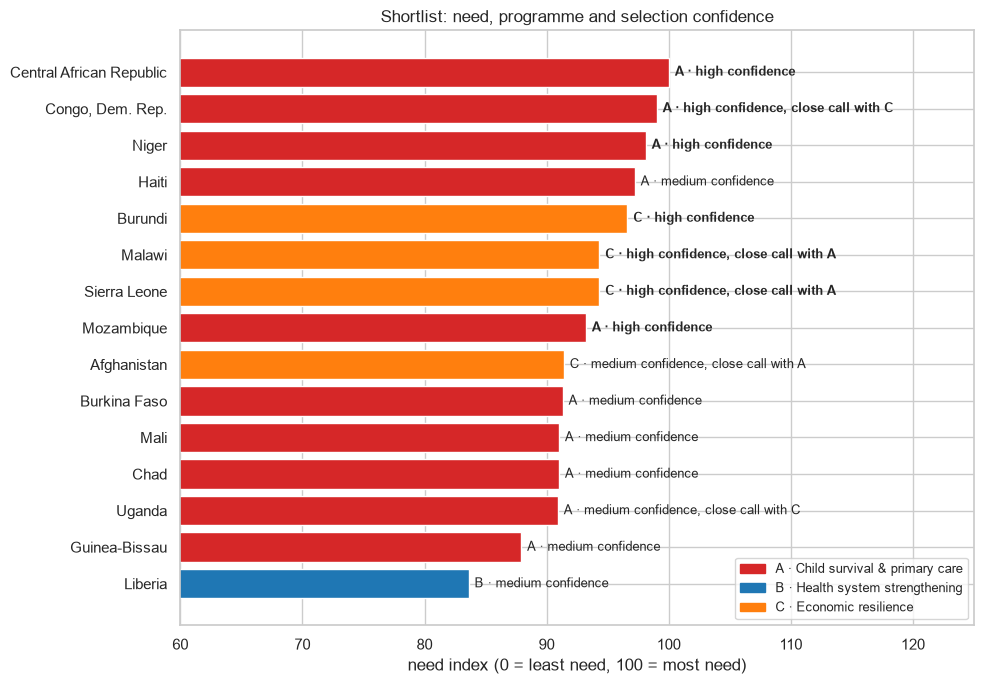

In [2]:
d = short.sort_values("need_index")
fig, ax = plt.subplots(figsize=(10, 7))
ax.barh(d.index, d["need_index"], color=d["programme"].map(PROG_COLORS))
for i, (c, r) in enumerate(d.iterrows()):
    prog = "" if r.programme_confidence == "Clear" else f", close call with {r.runner_up}"
    weight = "bold" if r.selection_confidence == "High" else "normal"
    ax.text(r.need_index + 0.5, i, f"{r.programme} · {r.selection_confidence.lower()} confidence{prog}", va="center", fontsize=9, fontweight=weight)
ax.set_xlim(60, 125)
ax.set_xlabel("need index (0 = least need, 100 = most need)")
handles = [plt.Rectangle((0, 0), 1, 1, color=PROG_COLORS[p]) for p in "ABC"]
ax.legend(handles, [PROG_NAMES[p] for p in "ABC"], loc="lower right", fontsize=9)
ax.set_title("Shortlist: need, programme and selection confidence")
plt.tight_layout()

In [3]:
table = short[["rank", "programme_name", "need_index", "top15_share", "selection_confidence", "programme_confidence", "reasoning"]].copy()
table.columns = ["Rank", "Programme", "Need index", "Selected in % of scenarios", "Selection confidence", "Programme fit", "Why"]
table["Selected in % of scenarios"] = (table["Selected in % of scenarios"] * 100).round(0).astype(int)
(table.style
    .format({"Need index": "{:.1f}"})
    .map(lambda v: "color: #2ca02c; font-weight: bold" if v in ("High", "Clear") else "color: #b26b00", subset=["Selection confidence", "Programme fit"])
    .set_properties(subset=["Why"], **{"text-align": "left", "font-size": "11px"}))

,Rank,Programme,Need index,Selected in % of scenarios,Selection confidence,Programme fit,Why
country,,,,,,,
Central African Republic,1,A · Child survival,100.0,98,High,Clear,"child mortality 149/1,000, 5.2 children per woman, life expectancy 48 y"
"Congo, Dem. Rep.",2,A · Child survival,99.0,99,High,Close call,"child mortality 116/1,000, 6.5 children per woman, life expectancy 58 y; close call with C"
Niger,3,A · Child survival,98.1,98,High,Clear,"child mortality 123/1,000, 7.5 children per woman, life expectancy 59 y"
Haiti,4,A · Child survival,97.2,75,Medium,Clear,"child mortality 208/1,000, 3.3 children per woman, life expectancy 32 y; note: 2010 earthquake: mortality and life expectancy reflect an acute shock"
Burundi,5,C · Economic resilience,96.6,97,High,Clear,"inflation 12.3%, exports 9% of GDP, income 764 USD"
Sierra Leone,6,C · Economic resilience,94.3,95,High,Close call,"inflation 17.2%, exports 17% of GDP, income 1,220 USD; close call with A"
Malawi,7,C · Economic resilience,94.3,88,High,Close call,"inflation 12.1%, exports 23% of GDP, income 1,030 USD; close call with A"
Mozambique,8,A · Child survival,93.2,97,High,Clear,"child mortality 101/1,000, 5.6 children per woman, life expectancy 54 y"
Afghanistan,9,C · Economic resilience,91.4,75,Medium,Close call,"inflation 9.4%, exports 10% of GDP, income 1,610 USD; close call with A"


In [4]:
reserve = res[res["reserve"]].sort_values("top15_share", ascending=False)
print("Reserve list (next in line):", ", ".join(f"{c} ({v:.0%})" for c, v in reserve["top15_share"].items()))

Reserve list (next in line): Guinea (58%), Togo (38%), Lesotho (28%), Zambia (21%), Gambia (17%)


## 2. Evidence

### 2.1 "Need" can be measured, and countries fall into four types

One single dimension explains **53 %** of all differences between the 167 countries: child mortality, fertility, life expectancy and income move together. We use it as the **need index**. Grouping countries on the main dimensions gives four types, and only one of them matches the foundation's mission.

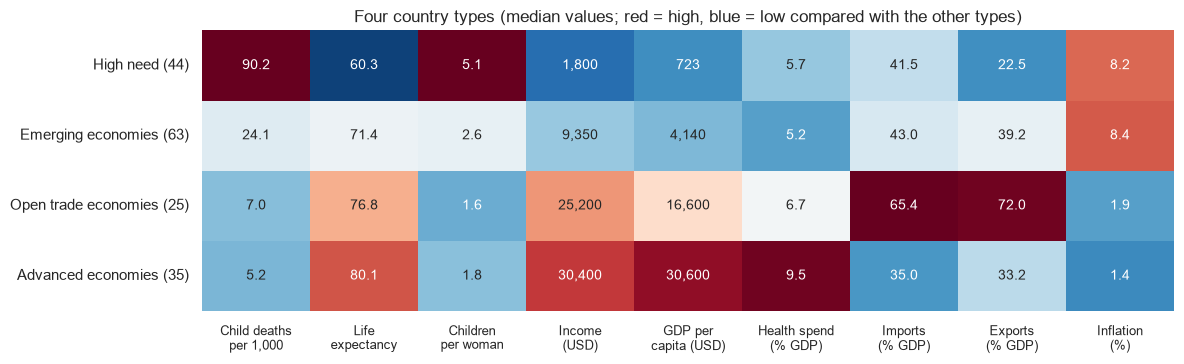

In [5]:
show = ["child_mort", "life_expec", "total_fer", "income", "gdpp", "health", "imports", "exports", "inflation"]
labels = ["Child deaths\nper 1,000", "Life\nexpectancy", "Children\nper woman", "Income\n(USD)", "GDP per\ncapita (USD)", "Health spend\n(% GDP)", "Imports\n(% GDP)", "Exports\n(% GDP)", "Inflation\n(%)"]
order = ["High need", "Emerging economies", "Open trade economies", "Advanced economies"]
p = prof.loc[order, show]
pz = (p - p.mean()) / p.std()
sizes = res["type"].value_counts()

fig, ax = plt.subplots(figsize=(12, 3.8))
sns.heatmap(pz, annot=p.map(lambda v: f"{v:,.0f}" if abs(v) >= 100 else f"{v:.1f}"), fmt="", cmap="RdBu_r", center=0, cbar=False, ax=ax, annot_kws={"size": 10})
ax.set_xticklabels(labels, rotation=0, fontsize=9)
ax.set_yticklabels([f"{t} ({sizes[t]})" for t in order], rotation=0)
ax.set_ylabel("")
ax.set_title("Four country types (median values; red = high, blue = low compared with the other types)")
plt.tight_layout()

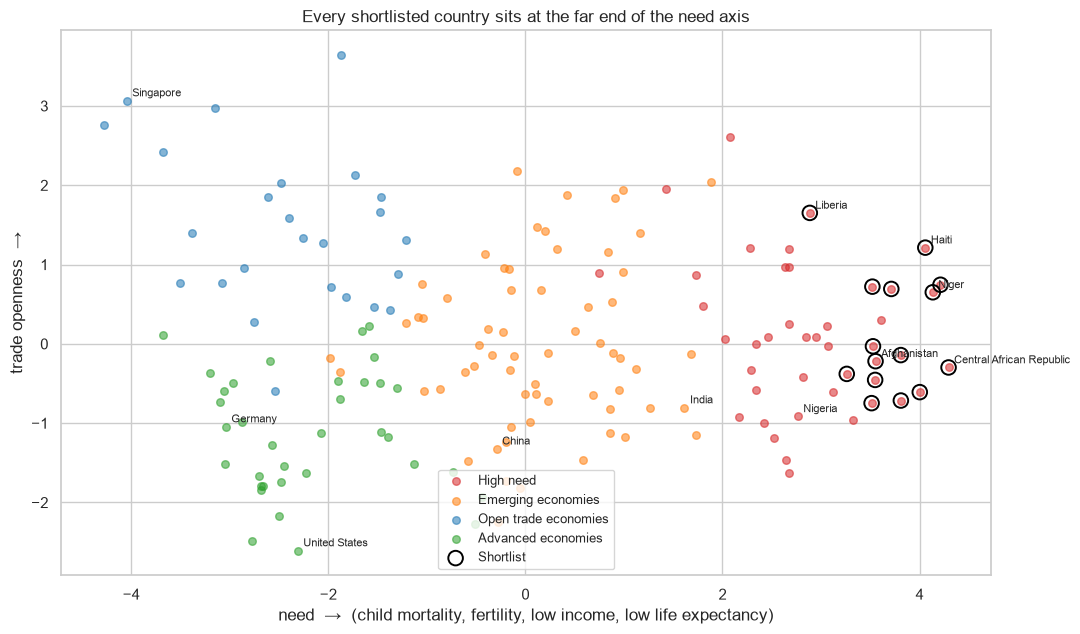

In [6]:
colors = {"High need": "#d62728", "Emerging economies": "#ff7f0e", "Open trade economies": "#1f77b4", "Advanced economies": "#2ca02c"}
fig, ax = plt.subplots(figsize=(11, 6.5))
for t in order:
    m = res["type"] == t
    ax.scatter(res.loc[m, "PC1"], res.loc[m, "PC2"], s=30, alpha=0.55, color=colors[t], label=t)
s = res[res["shortlisted"]]
ax.scatter(s["PC1"], s["PC2"], s=110, facecolors="none", edgecolors="black", lw=1.4, label="Shortlist")
for c in ["Central African Republic", "Niger", "Haiti", "Liberia", "Afghanistan", "India", "China", "Germany", "Singapore", "United States", "Nigeria"]:
    ax.annotate(c, (res.loc[c, "PC1"], res.loc[c, "PC2"]), fontsize=8, xytext=(4, 3), textcoords="offset points")
ax.set_xlabel("need  →  (child mortality, fertility, low income, low life expectancy)")
ax.set_ylabel("trade openness  →")
ax.set_title("Every shortlisted country sits at the far end of the need axis")
ax.legend(loc="lower center", fontsize=9)
plt.tight_layout()

### 2.2 The shortlist holds up under different assumptions

A critic can always say "you weighted the indicators wrongly". So we re-ran the selection **1,000 times with different weights** for child mortality, life expectancy, fertility, income and GDP, plus small measurement noise. The chart shows how often each country makes the top 15.

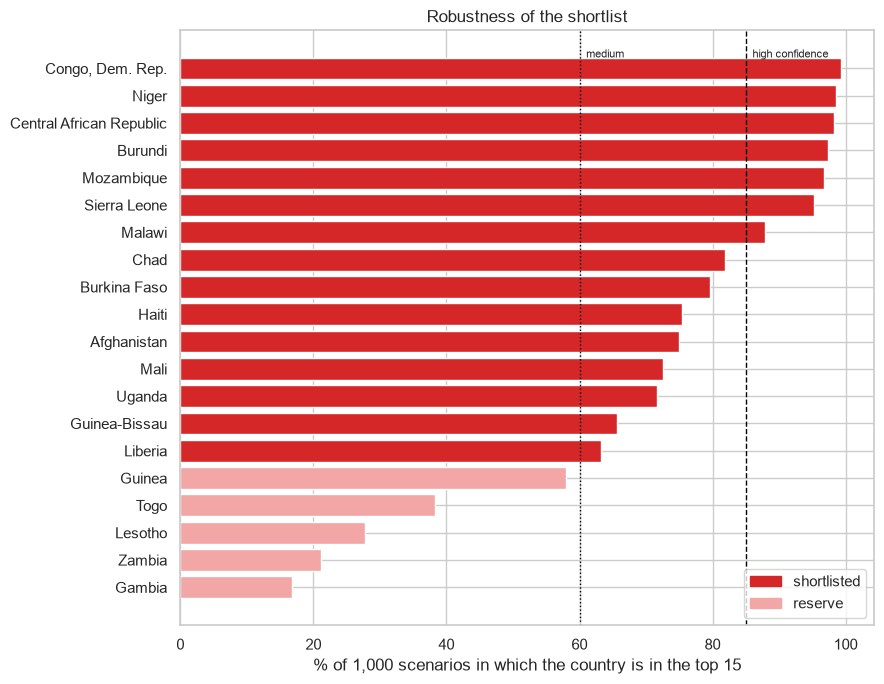

In [7]:
top = res[res["type"] == "High need"].sort_values("top15_share", ascending=False).head(20).iloc[::-1]
col = np.where(top["shortlisted"], "#d62728", np.where(top["reserve"], "#f2a6a6", "#cccccc"))
fig, ax = plt.subplots(figsize=(9, 7))
ax.barh(top.index, top["top15_share"] * 100, color=col)
ax.axvline(85, ls="--", color="black", lw=1)
ax.text(86, len(top) - 0.6, "high confidence", fontsize=8)
ax.axvline(60, ls=":", color="black", lw=1)
ax.text(61, len(top) - 0.6, "medium", fontsize=8)
ax.set_xlabel("% of 1,000 scenarios in which the country is in the top 15")
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in ["#d62728", "#f2a6a6"]]
ax.legend(handles, ["shortlisted", "reserve"], loc="lower right")
ax.set_title("Robustness of the shortlist")
plt.tight_layout()

**How to read it:** 7 countries are on the list in almost every scenario. The lower half is solid but depends somewhat on how much weight one puts on child mortality versus income. The last place is a genuine judgement call between **Liberia** (lowest income) and **Guinea** (higher child mortality).

## 3. Data science perspective: how the board's questions became data science jobs

| Board question | What we had to find out | Data science job | Method | Key choice we made |
|---|---|---|---|---|
| Who needs help most? | A single, defensible definition of need | Dimensionality reduction | PCA, first component = need index | Log income/GDP/mortality, standardise all indicators |
| Are there different types of countries? | Groups without any labels | Clustering | k-means (k = 4) on 4 principal components | k chosen by interpretability + stability, not only by score |
| Which ≤ 15 countries? | Ranking within the relevant group | Ranking + filtering | Need index within the High need type | Selection by robustness, not by a single score |
| Which programme? | Each country's relative weakness | Rule-based profile scoring | z-scores within the High need type for A, B, C | Transparent rules instead of a black box |
| How sure are we? | What changes if assumptions change | Sensitivity analysis | Bootstrap, other k/algorithms, 1,000 weightings | Report confidence per country |

**Data problems we fixed before modelling:** Myanmar's trade figures (≈ 0 % of GDP) and Nigeria's inflation (104 %) were implausible and imputed. Haiti's values reflect the 2010 earthquake and are flagged. Income-type variables were log-transformed, outliers winsorised and all indicators standardised so no single unit dominates.

## 4. Recommendation (final slide)

| | |
|---|---|
| **Need** | One development axis explains 53 % of the variation across nine indicators. It is driven by child mortality, fertility, life expectancy and income. |
| **Types** | Four country types: high need (44), emerging economies (63), open trade economies (25) and advanced economies (35). Only the high-need type is relevant for the foundation's mission. |
| **Shortlist** | 15 countries from the high-need type: 10 × A (child survival), 4 × C (economic resilience), 1 × B (health system). Reserve: Guinea, Togo, Lesotho, Zambia, Gambia. |
| **Confidence** | The high-need type is stable across seeds, k and algorithms. 7 of 15 countries are high-confidence picks; the last places and 5 programme assignments are close calls and need local expert review. |

**Limitations to state.**
1. **Coverage:** Somalia, South Sudan, Ethiopia, Zimbabwe, Syria and North Korea are not in the data. The shortlist ranks the countries *in this dataset*.
2. **Need is not impact:** governance, conflict, absorptive capacity and other donors' activities are missing, so we cannot say where a euro achieves most.
3. **Snapshot:** data from around 2010 to 2015, no trends. Haiti's numbers are distorted by the 2010 earthquake.
4. **Averages hide inequality** inside large countries (e.g. regions of Nigeria or the DR Congo).
5. **Modelling choices:** clusters depend on k, scaling and algorithm, and the need index assumes that its underlying drivers are what matters. The programme rules use only a handful of indicators.
6. **Budget arithmetic:** 15 × €4 m = €60 m, i.e. the entire three-year budget at the minimum effective grant size. The board may prefer the 7 high-confidence countries plus a reserve for larger grants.

**Next steps.** Add trend, governance and conflict data; check the missing crisis countries separately; validate the five close-call programme assignments with regional experts.

## 5. Prepared answers

**"Why these countries and not others?"**
They are the countries with the highest need on the measure that best summarises the data, and they stay in the top 15 under most alternative weightings. Countries just below the line (Guinea, Togo, Lesotho, Zambia, Gambia) are on the reserve list; the chart in 2.2 shows exactly how close they are.

**"Why did you choose four groups?"**
Two groups only separates rich from poor, which is the GDP ranking the board did not want. Three and four groups fit the data equally well, but four groups are easier to explain because they separate trade hubs from other advanced economies. Most importantly, the high-need group is the same with three or four groups, so the shortlist does not depend on this choice.